# FADEx — Validating the SND distortion metric



## Setup

In [1]:
# Colab: install the FADEx package and the extra dependencies used below
%pip install -q fadex-exp umap-learn ucimlrepo

In [2]:
# --- Standard library ---
from pathlib import Path
import warnings

# --- Numerics / ML ---
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.datasets import fetch_openml, load_breast_cancer, load_wine
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

# --- Dimensionality reduction ---
from sklearn.manifold import TSNE
import umap

# --- Plotting ---
import colorsys
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# Compatibility shim: the current FADEx release calls `matplotlib.cm.get_cmap`,
# which was removed in Matplotlib 3.11. Restore it before importing FADEx.
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

from fadex import FADEx

warnings.filterwarnings("ignore", category=UserWarning)
FIG_DIR = Path("figures_snd")
FIG_DIR.mkdir(exist_ok=True)

---
# Part I — SND and nearest neighbours on MNIST (Fig. 4)

t-SNE (`perplexity=30`, `early_exaggeration=24`, `learning_rate=600`, `init='pca'`) is applied to a stratified random
sample of 5,000 MNIST digits, and FADEx is run on every point.

FADEx settings: `n_neighbors=250`. The usual rule of thumb is ~10% of the dataset (500), but each digit class has only
~500 samples, so 500 neighbours would span whole classes and the estimate would no longer be local.
Because MNIST has 784 features (> 50), constant-feature removal and local PCA (95% variance) are enabled.

In [3]:
# ---------------- Parameters ----------------
MNIST_N = 5_000          # number of sampled digits
SEED = 42                # sampling and t-SNE seed

TSNE_PARAMS = dict(
    n_components=2,
    init="pca",
    perplexity=30,
    early_exaggeration=24,
    learning_rate=600,
    max_iter=4000,
    metric="euclidean",
    random_state=SEED,
)

FADEX_NEIGHBORS = 250    # neighbourhood size for the Jacobian estimation
KNN_PLOT = 50            # neighbours drawn in Fig. 4C
SAVE_FIGS = True

### Data and t-SNE embedding

In [4]:
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X_all = mnist.data.astype(np.float32)        # (70000, 784)
y_all = mnist.target

# Stratified random sample of MNIST_N digits
sss = StratifiedShuffleSplit(n_splits=1, train_size=MNIST_N, random_state=SEED)
idx, _ = next(sss.split(X_all, y_all))
X_mnist = X_all[idx] / 255.0                 # pixel intensities in [0, 1]
labels = y_all[idx].astype(int)

print("MNIST sample:", X_mnist.shape)

X_tsne = TSNE(**TSNE_PARAMS).fit_transform(X_mnist)

MNIST sample: (5000, 784)


### FADEx on every instance

In [5]:
exp_mnist = FADEx(
    high_dim_data=X_mnist,
    low_dim_data=X_tsne,
    n_neighbors=FADEX_NEIGHBORS,
    remove_const_feat=True,   # drop near-constant pixels in each neighbourhood
    use_pca=True,             # local PCA (95% variance): 784 features > 50
    ridge_lambda=0.1,
)
exp_mnist._fit_all()          # caches all_phis, all_norms (SND) and all_jacs

snd = np.asarray(exp_mnist.all_norms, dtype=float)
print(f"SND  min={snd.min():.3f}  median={np.median(snd):.3f}  max={snd.max():.3f}")
print(f"Fraction of points with SND > 1 (stretching): {(snd > 1).mean():.1%}")

[FADEx] Processing Instances:   0%|          | 0/5000 [00:00<?, ?instance/s]

SND  min=7.705  median=51.391  max=101.690
Fraction of points with SND > 1 (stretching): 100.0%


### Plotting helpers


In [6]:
def build_snd_cmap(n=256, darken=0.85):
    # Darkened Spectral_r colormap used in Fig. 4
    spectral = plt.get_cmap("Spectral_r", n)
    colors = []
    for i in range(n):
        r, g, b, a = spectral(i / (n - 1))
        h, s, v = colorsys.rgb_to_hsv(r, g, b)
        colors.append((*colorsys.hsv_to_rgb(h, s, v * darken), a))
    return mcolors.LinearSegmentedColormap.from_list("spectral_r_dark", colors)


SND_CMAP = build_snd_cmap()


def snd_norm(norms):
    # Diverging normalisation centred at 1 (no distortion)
    vmin = min(float(np.nanmin(norms)), 1.0 - 1e-9)
    vmax = max(float(np.nanmax(norms)), 1.0 + 1e-9)
    return mcolors.TwoSlopeNorm(vcenter=1.0, vmin=vmin, vmax=vmax)


def add_snd_colorbar(fig, ax, norm):
    sm = cm.ScalarMappable(cmap=SND_CMAP, norm=norm)
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks([norm.vmin, 1.0, norm.vmax])
    cbar.set_ticklabels([f"{norm.vmin:.2f}", "1.00", f"{norm.vmax:.2f}"])
    cbar.set_label("SND  (shrinking  →  stretching)", rotation=270, labelpad=18)


def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / name, bbox_inches="tight", dpi=300)

### Fig. 4A — t-SNE embedding coloured by digit

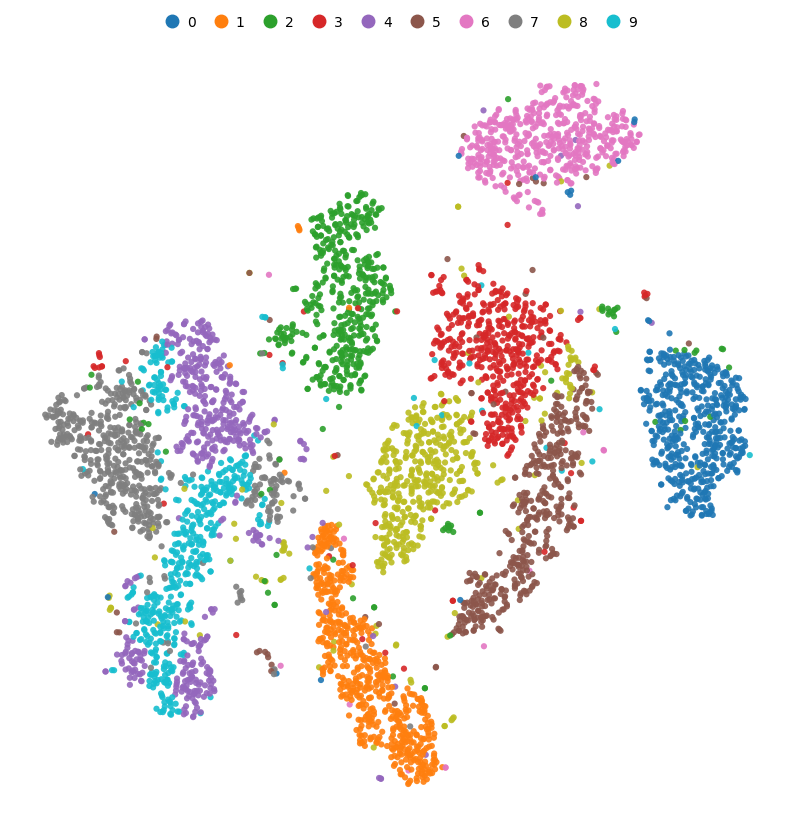

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap="tab10", vmin=0, vmax=9,
           s=20, alpha=0.9, linewidths=0, rasterized=True)
handles = [Line2D([], [], marker="o", linestyle="None", markersize=9,
                  color=plt.get_cmap("tab10")(d), label=str(d)) for d in range(10)]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.06),
          ncol=10, frameon=False, handletextpad=0.1, columnspacing=0.8)
ax.axis("off")
save(fig, "fig4A_mnist_tsne_labels.pdf")
plt.show()

### Fig. 4B — SND distortion map

Paper finding: most points are red, i.e. t-SNE mainly **stretches** local neighbourhoods.

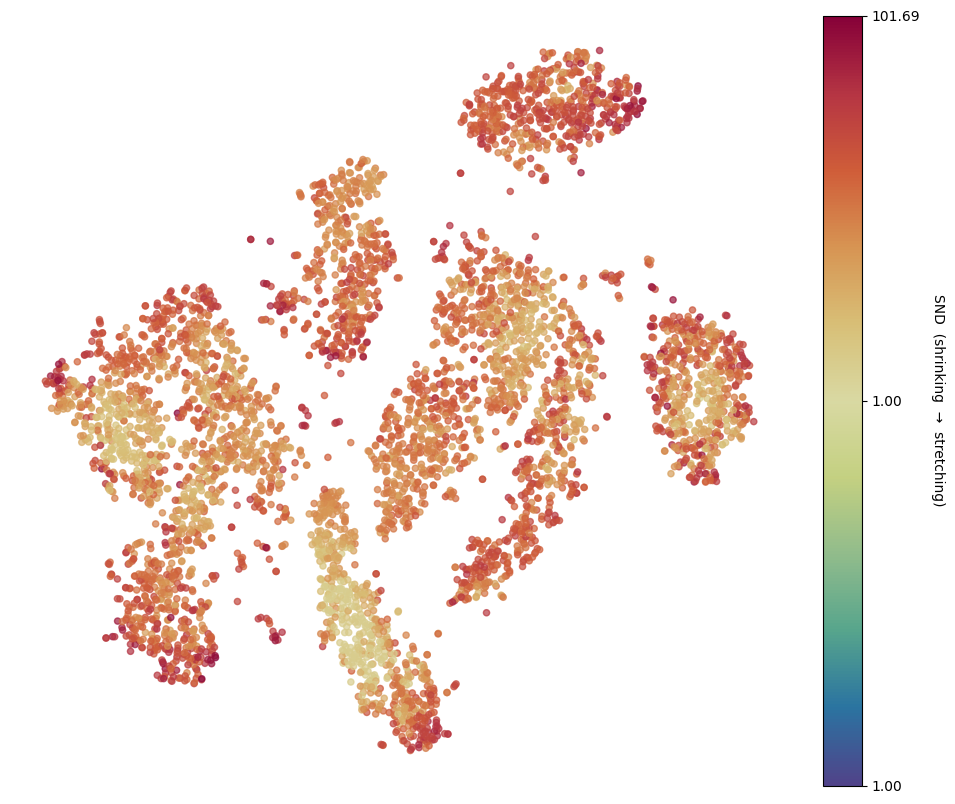

In [8]:
norm = snd_norm(snd)

fig, ax = plt.subplots(figsize=(11, 10))
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=snd, cmap=SND_CMAP, norm=norm,
           s=20, alpha=0.7, rasterized=True)
add_snd_colorbar(fig, ax, norm)
ax.axis("off")
save(fig, "fig4B_mnist_snd.pdf")
plt.show()

### Fig. 4C — High-dimensional neighbourhoods of the highest- and lowest-SND points

For the point with the **largest** SND (highest distortion) and the point with the **smallest** SND, we draw their
`KNN_PLOT = 50` nearest neighbours **in the original 784-dimensional space** at their 2D positions.
Neighbours are coloured by their own SND and linked to the query point (star).

Paper finding: the neighbours of the high-SND point are scattered across the layout, whereas those of the low-SND
point stay together.

Highest SND: point 3497 (SND = 101.690)
Lowest  SND: point 812 (SND = 7.705)


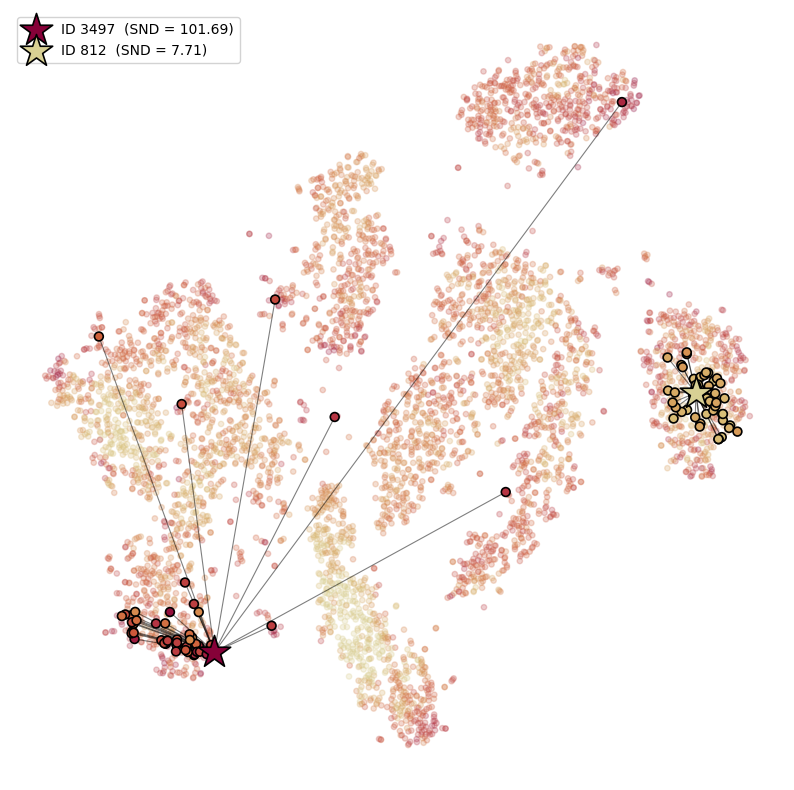

In [9]:
def plot_high_dim_neighbors(exp, query_points, n_neighbors=50, base_alpha=0.25,
                            figsize=(10, 10), fname=None):
    # Draws the high-dimensional k-NN of each query point in the 2D embedding
    low = np.asarray(exp.low_dim_data, dtype=float)
    high = np.asarray(exp.high_dim_data, dtype=float)
    norms = np.asarray(exp.all_norms, dtype=float)
    norm = snd_norm(norms)
    colors = cm.ScalarMappable(cmap=SND_CMAP, norm=norm).to_rgba(norms)

    # k+1 because each point is its own nearest neighbour
    nn = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(high)
    _, idx_high = nn.kneighbors(high[query_points])
    idx_high = idx_high[:, 1:]

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(low[:, 0], low[:, 1], c=norms, cmap=SND_CMAP, norm=norm,
               s=15, alpha=base_alpha, rasterized=True)

    for pt, nb in zip(query_points, idx_high):
        px, py = low[pt]
        for j in nb:                                  # links query -> neighbour
            ax.plot([px, low[j, 0]], [py, low[j, 1]], color="black",
                    linewidth=0.8, alpha=0.5, zorder=2)
        ax.scatter(low[nb, 0], low[nb, 1], s=40, c=colors[nb],
                   edgecolors="black", linewidths=1.2, zorder=3)
        ax.scatter(px, py, s=600, marker="*", c=[colors[pt]], edgecolors="black",
                   linewidths=1.2, zorder=4, label=f"ID {pt}  (SND = {norms[pt]:.2f})")

    ax.legend(loc="best", fontsize=10, framealpha=0.85)
    ax.axis("off")
    if fname:
        save(fig, fname)
    plt.show()


idx_max = int(np.nanargmax(snd))   # highest distortion (strongest stretching)
idx_min = int(np.nanargmin(snd))   # lowest SND
print(f"Highest SND: point {idx_max} (SND = {snd[idx_max]:.3f})")
print(f"Lowest  SND: point {idx_min} (SND = {snd[idx_min]:.3f})")

plot_high_dim_neighbors(exp_mnist, [idx_max, idx_min], n_neighbors=KNN_PLOT,
                        fname="fig4C_mnist_high_dim_knn.pdf")

*Optional:* interactive exploration — hover over a point to see its ID and SND.

In [10]:
exp_mnist.interactive_plot(show_features=False)

---
# Part II — SND vs. the local distance ratio δ = d/D (Table 2)


In [11]:
# ---------------- Parameters ----------------
SEED_DR = 71              # single seed for t-SNE / UMAP
N_EVAL = 500              # points evaluated per (dataset, method)

DR_MODELS = {
    "t-SNE": TSNE(n_components=2, perplexity=50, random_state=SEED_DR),
    "UMAP":  umap.UMAP(n_components=2, n_neighbors=50, random_state=SEED_DR),
}

# Neighbourhood size k used for both SND and d/D, per dataset
NEIGHBORS = {
    "Wine": 50,
    "Dermatology": 50,
    "Breast Cancer": 100,
    "Dry Bean": 400,
    "Musk Version 2": 200,
    "Isolet": 400,
    "MNIST": 350,
}


rng = np.random.default_rng(42)   # shared generator (see notes above)

### Datasets

In [12]:
def drop_duplicate_rows(X, y):
    # Removes exact duplicate rows while keeping the original row order
    X = np.asarray(X)
    X_u, first_idx = np.unique(X, axis=0, return_index=True)
    order = np.argsort(first_idx)
    keep = first_idx[order]
    return X_u[order], y.iloc[keep].reset_index(drop=True)


datasets = {}

# Wine (178 x 13)
datasets["Wine"] = StandardScaler().fit_transform(load_wine().data)

# Dermatology (366 x 34; rows with missing age are dropped)
derm = fetch_ucirepo(id=33)
datasets["Dermatology"] = StandardScaler().fit_transform(derm.data.features.dropna())

# Breast Cancer (569 x 30)
datasets["Breast Cancer"] = StandardScaler().fit_transform(load_breast_cancer().data)

# Dry Bean (13611 x 16, duplicates removed)
dry_bean = fetch_ucirepo(id=602)
X_db = dry_bean.data.features.dropna()
X_db, _ = drop_duplicate_rows(X_db, dry_bean.data.targets.loc[X_db.index])
datasets["Dry Bean"] = StandardScaler().fit_transform(X_db)

# Musk Version 2 (6598 x 166, duplicates removed)
musk = fetch_ucirepo(id=75)
X_musk, _ = drop_duplicate_rows(musk.data.features, musk.data.targets)
datasets["Musk Version 2"] = StandardScaler().fit_transform(X_musk)

# Isolet (7797 x 617, duplicates removed, rows shuffled with the shared generator)
isolet = fetch_ucirepo(id=54)
X_iso, _ = drop_duplicate_rows(isolet.data.features, isolet.data.targets)
perm = rng.choice(len(X_iso), size=len(X_iso), replace=False)
datasets["Isolet"] = StandardScaler().fit_transform(X_iso[perm])

# MNIST (random sample of 5000 x 784)
mnist_df = fetch_openml("mnist_784", version=1, as_frame=True, parser="auto")
X_mn = mnist_df.data.sample(n=5000, random_state=42).dropna()
datasets["MNIST"] = StandardScaler().fit_transform(X_mn)

for name, X in datasets.items():
    print(f"{name:15s} {X.shape}")

Wine            (178, 13)
Dermatology     (358, 34)
Breast Cancer   (569, 30)
Dry Bean        (13543, 16)
Musk Version 2  (6581, 166)
Isolet          (7797, 617)
MNIST           (5000, 784)


### Metrics

In [13]:
def normalize_01(X):
    # Min-max normalisation to [0, 1] per feature
    mins, maxs = X.min(axis=0), X.max(axis=0)
    span = maxs - mins
    span[span == 0] = 1.0                  # constant features
    return (X - mins) / span


def compute_embedding(X, dr_model, seed):
    # Fits a fresh copy of the DR model with the given seed
    model = clone(dr_model).set_params(random_state=seed)
    return np.asarray(model.fit_transform(X), dtype=np.float32)


def distance_ratio(hd, ld, k, samples):
    # delta = mean 2D distance / mean high-dim distance over the k high-dim neighbours
    nn = NearestNeighbors(n_neighbors=k + 1).fit(hd)
    d_high, idx = nn.kneighbors(hd[samples])
    d_high, idx = d_high[:, 1:], idx[:, 1:]          # drop the point itself
    d_low = np.linalg.norm(ld[idx] - ld[samples][:, None, :], axis=2)
    mean_high = d_high.mean(axis=1)
    return np.where(mean_high > 0, d_low.mean(axis=1) / mean_high, np.inf)


def snd_fadex(hd, ld, k, samples):
    # SND (spectral norm of the estimated Jacobian) for each sampled point
    exp = FADEx(high_dim_data=hd, low_dim_data=ld, n_neighbors=k,
                use_pca=True, remove_const_feat=True)
    return np.array([exp.fit(i, show=False)["SND"] for i in tqdm(samples, leave=False)])


def pearson(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    return pearsonr(x[mask], y[mask])[0]

### Run

In [14]:
rows = []
for ds_name, hd in datasets.items():
    hd = np.asarray(hd, dtype=np.float32)
    n, k = hd.shape[0], NEIGHBORS[ds_name]
    print(f"\n=== {ds_name} | n={n} | k={k} ===")

    for dr_name, dr_model in DR_MODELS.items():
        print(f"  -> {dr_name}")
        ld = compute_embedding(hd, dr_model, SEED_DR)

        samples = rng.choice(n, size=N_EVAL, replace=False) if n > N_EVAL else np.arange(n)

        hd_n, ld_n = normalize_01(hd), normalize_01(ld)
        delta = distance_ratio(hd_n, ld_n, k, samples)
        snd_vals = snd_fadex(hd_n, ld_n, k, samples)

        rows.append({"dataset": ds_name, "method": dr_name, "n_eval": len(samples),
                     "pearson_r": pearson(snd_vals, delta),
                     "snd": snd_vals, "delta": delta})


=== Wine | n=178 | k=50 ===
  -> t-SNE


  0%|          | 0/178 [00:00<?, ?it/s]

  -> UMAP


  0%|          | 0/178 [00:00<?, ?it/s]


=== Dermatology | n=358 | k=50 ===
  -> t-SNE


  0%|          | 0/358 [00:00<?, ?it/s]

... (18 outputs left out)


=== MNIST | n=5000 | k=350 ===
  -> t-SNE


  0%|          | 0/500 [00:00<?, ?it/s]

  -> UMAP


  0%|          | 0/500 [00:00<?, ?it/s]

### Results

In [15]:
res = pd.DataFrame(rows)
table = res.pivot(index="dataset", columns="method", values="pearson_r")
ds_order = [d for d in datasets if d in table.index]       # dataset order
table = table.loc[ds_order, ["t-SNE", "UMAP"]]
display(table.round(2))

method,t-SNE,UMAP
dataset,,
Wine,0.79,0.73
Dermatology,0.86,0.80
Breast Cancer,0.92,0.90
Dry Bean,0.89,0.92
Musk Version 2,0.47,0.80
Isolet,0.63,0.68
MNIST,0.59,0.66


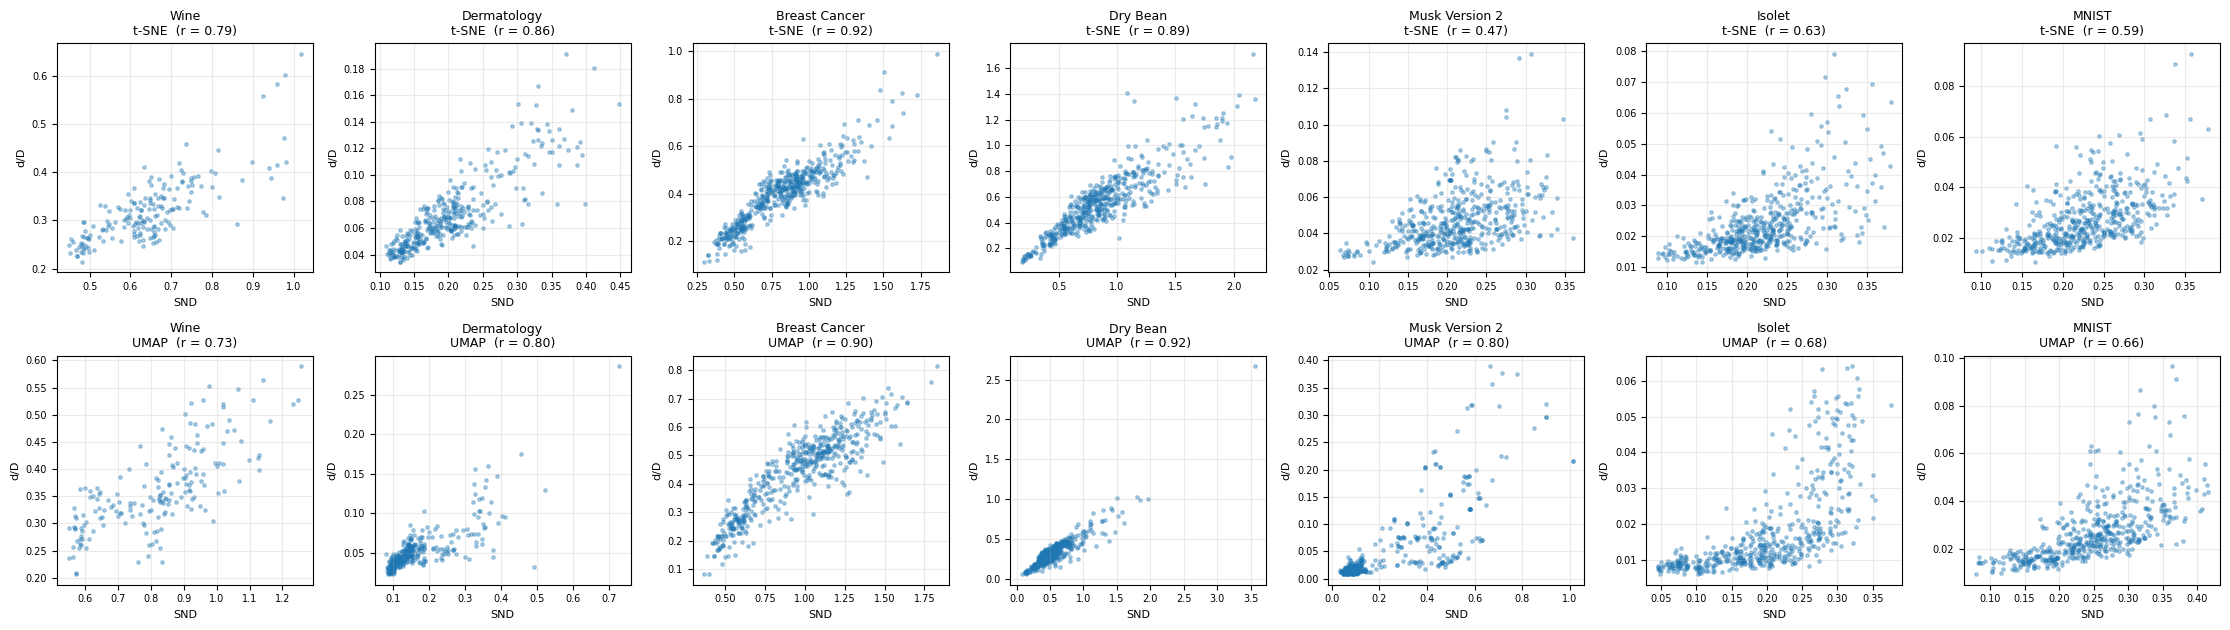

In [16]:
# Scatter of SND vs delta for every (dataset, method)
fig, axes = plt.subplots(2, len(ds_order), figsize=(3.2 * len(ds_order), 6.4), squeeze=False)
for col, ds_name in enumerate(ds_order):
    for row, dr_name in enumerate(DR_MODELS):
        r = res[(res.dataset == ds_name) & (res.method == dr_name)].iloc[0]
        ax = axes[row, col]
        ax.scatter(r.snd, r.delta, s=6, alpha=0.35)
        ax.set_title(f"{ds_name}\n{dr_name}  (r = {r.pearson_r:.2f})", fontsize=9)
        ax.set_xlabel("SND", fontsize=8)
        ax.set_ylabel("d/D", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.25)
plt.tight_layout()
save(fig, "table2_snd_vs_delta_scatter.pdf")
plt.show()